# Влияние случайных шумовых признаков на качество модели
**Сагун Александр, № 40 · Основы машинного обучения**

## 1. Исследовательский вопрос
Как меняется качество классификации, если добавить признаки, не несущие информации о классе? Сравниваются пять алгоритмов на трёх наборах данных и проверяется польза отбора признаков.

Все вычисления и графики находятся в этом notebook. Выводы ячеек сохранены. Для воспроизведения достаточно установить зависимости и выполнить все ячейки сверху вниз.

## 2. Что такое шумовой признак
Строка матрицы X — объект, столбец — измеренная характеристика. Метка y — правильный класс. Добавим к X случайные числа, не используя y: например, результат броска виртуального кубика для каждого объекта. Такие числа могут случайно совпадать с классами в небольшой выборке, хотя в механизме генерации никакой связи нет.

В работе используется N(0,1): нормальное распределение со средним 0 и стандартным отклонением 1. Нулевое среднее не значит, что каждое значение равно нулю. Исходные признаки и ответы не меняются.

### Реализация эксперимента
Ниже определены генераторы данных, модели, процедура повторений и построение графиков. Первые три кодовые ячейки определяют функции; следующая запускает полный эксперимент. На Python 3.12 выполнение занимает несколько минут.

Используются отдельные seeds для данных, разбиений, шума и моделей. Подбор доли признаков выполняется только во внутренней кросс-валидации на обучающей части.

In [1]:
"""Влияние независимых шумовых признаков: воспроизводимый эксперимент.

Все числа в отчёте получаются этим модулем. Внешние данные не скачиваются.
"""
from __future__ import annotations

import json
import platform
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.datasets import load_breast_cancer, make_classification, make_moons
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, log_loss
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

COUNTS = [0, 10, 25, 50, 100, 200]
SEEDS = [11, 23, 37, 51, 71]
MODEL_NAMES = ["LogisticRegression", "KNN", "DecisionTree", "RandomForest", "MLP"]
LABELS = {"classification": "Синтетическая классификация", "moons": "Две луны", "breast_cancer": "Breast Cancer Wisconsin"}
COLORS = ["#3873A3", "#B45D3B", "#9371A6", "#218570", "#B58A22"]


def datasets():
    """Исходные данные фиксированы; меняются только разбиение, шум и seed модели."""
    X1, y1 = make_classification(n_samples=1000, n_features=10,
        n_informative=8, n_redundant=2, n_repeated=0,
        class_sep=1.0, flip_y=0.01, random_state=2026)
    X2, y2 = make_moons(n_samples=1000, noise=0.25, random_state=2026)
    X3, y3 = load_breast_cancer(return_X_y=True)
    return {"classification": (X1, y1), "moons": (X2, y2), "breast_cancer": (X3, y3)}


def prepare(X, y, seed):
    indices = np.arange(len(y))
    train, test = train_test_split(indices, test_size=0.30, stratify=y, random_state=seed)
    # Seed шума отличается от seed разбиения. y не участвует в генерации.
    noise = np.random.default_rng(10_000 + seed).normal(size=(len(y), max(COUNTS)))
    assert not np.intersect1d(train, test).size
    assert len(train) + len(test) == len(y)
    return train, test, noise


def add_noise(X, noise, count):
    """Вложенные наборы: первые 10 шумовых столбцов те же при p=10 и p=200."""
    return np.column_stack([X, noise[:, :count]])


def model(name, seed):
    estimators = {
        "LogisticRegression": lambda: LogisticRegression(C=1.0, max_iter=2000),
        "KNN": lambda: KNeighborsClassifier(n_neighbors=15),
        "DecisionTree": lambda: DecisionTreeClassifier(random_state=seed),
        "RandomForest": lambda: RandomForestClassifier(n_estimators=100, max_features="sqrt", n_jobs=1, random_state=seed),
        "MLP": lambda: MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", solver="adam", alpha=0.0001,
            learning_rate_init=0.003, max_iter=500, early_stopping=True,
            validation_fraction=0.15, n_iter_no_change=20, random_state=seed),
    }
    # Деревьям масштабирование не требуется. Единый pipeline упрощает сравнение.
    return Pipeline([("scale", StandardScaler()), ("model", estimators[name]())])


def scores(estimator, Xtr, Xte, ytr, yte):
    pred = estimator.predict(Xte)
    return {"train_accuracy": accuracy_score(ytr, estimator.predict(Xtr)),
            "accuracy": accuracy_score(yte, pred),
            "balanced_accuracy": balanced_accuracy_score(yte, pred),
            "f1_macro": f1_score(yte, pred, average="macro"),
            "log_loss": log_loss(yte, estimator.predict_proba(Xte))}


def checked_fit(estimator, X, y):
    with warnings.catch_warnings(record=True) as found:
        warnings.simplefilter("always", ConvergenceWarning)
        estimator.fit(X, y)
    # Записываем предупреждения вместо их скрытия.
    return " | ".join(str(w.message) for w in found)

In [2]:
def run_experiments(output_dir):
    """450 основных обучений + 90 контролей + вложенный подбор отбора признаков."""
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    rows, controls, selections, geometry = [], [], [], []
    with threadpool_limits(limits=1):
        for dataset, (X, y) in datasets().items():
            for seed in SEEDS:
                train, test, noise = prepare(X, y, seed)
                yt, yv = y[train], y[test]
                # Одни и те же пары обучающих объектов для каждого p.
                rng = np.random.default_rng(30_000 + seed)
                a = rng.integers(0, len(train), size=5000)
                b = rng.integers(1, len(train), size=5000)
                b = (a + b) % len(train)  # пары всегда разных объектов
                for p in COUNTS:
                    Xp = add_noise(X, noise, p)
                    Xt, Xv = Xp[train], Xp[test]
                    Z = StandardScaler().fit_transform(Xt)
                    sq = (Z[a] - Z[b]) ** 2
                    distance = np.sqrt(sq.sum(axis=1))
                    geometry.append({"dataset": dataset, "seed": seed, "n_noise": p,
                        "original_sq_distance": sq[:, :X.shape[1]].sum(axis=1).mean(),
                        "noise_sq_distance": sq[:, X.shape[1]:].sum(axis=1).mean(),
                        "distance_cv": distance.std(ddof=1) / distance.mean()})
                    for name in MODEL_NAMES:
                        pipe = model(name, 20_000 + seed)
                        warning = checked_fit(pipe, Xt, yt)
                        row = {"dataset": dataset, "seed": seed, "model": name, "n_noise": p,
                            "n_original": X.shape[1], "n_train": len(train), "n_test": len(test),
                            **scores(pipe, Xt, Xv, yt, yv), "warnings": warning,
                            "n_iter": int(pipe[-1].n_iter_) if name == "MLP" else None}
                        rows.append(row)
                # Отрицательный контроль: исходные признаки полностью исключены.
                for name in MODEL_NAMES + ["Dummy"]:
                    pipe = model(name, 20_000 + seed) if name != "Dummy" else DummyClassifier(strategy="prior")
                    warning = checked_fit(pipe, noise[train], yt)
                    controls.append({"dataset": dataset, "seed": seed, "model": name,
                        **scores(pipe, noise[train], noise[test], yt, yv), "warnings": warning})
                # Отбор признаков: внешняя test-часть не участвует в выборе percentile.
                Xp = add_noise(X, noise, 200)
                pipe = Pipeline([("scale", StandardScaler()),
                    ("select", SelectPercentile(f_classif)),
                    ("model", KNeighborsClassifier(n_neighbors=15))])
                inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=40_000 + seed)
                search = GridSearchCV(pipe, {"select__percentile": [5, 10, 25, 50, 100]},
                    cv=inner, scoring="balanced_accuracy", n_jobs=1, error_score="raise")
                warning = checked_fit(search, Xp[train], yt)
                support = search.best_estimator_["select"].get_support()
                selections.append({"dataset": dataset, "seed": seed,
                    "percentile": search.best_params_["select__percentile"],
                    "selected_original": int(support[:X.shape[1]].sum()),
                    "selected_noise": int(support[X.shape[1]:].sum()),
                    "inner_cv_score": search.best_score_,
                    **scores(search, Xp[train], Xp[test], yt, yv), "warnings": warning})
                print(f"Готово: {dataset}, seed={seed}", flush=True)
    raw = pd.DataFrame(rows)
    assert len(raw) == 3 * len(SEEDS) * len(COUNTS) * len(MODEL_NAMES)
    assert raw[["accuracy", "balanced_accuracy", "f1_macro"]].ge(0).all().all()
    assert raw[["accuracy", "balanced_accuracy", "f1_macro"]].le(1).all().all()
    for filename, frame in [("metrics.csv", raw), ("noise_only.csv", pd.DataFrame(controls)),
                            ("selection.csv", pd.DataFrame(selections)), ("geometry.csv", pd.DataFrame(geometry))]:
        frame.to_csv(out / filename, index=False, float_format="%.10f")
    meta = {"author": "Сагун Александр", "student_number": "40", "seeds": SEEDS,
        "noise_counts": COUNTS, "test_size": 0.3, "noise": "independent N(0, 1)",
        "dataset_seed": 2026, "noise_seed_offset": 10000, "model_seed_offset": 20000,
        "inner_cv_seed_offset": 40000, "main_fits": len(raw), "control_fits": len(controls),
        "selection_fits": 15 * (5 * 3 + 1), "versions": {"python": platform.python_version(),
        "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
        "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__},
        "datasets": {k: {"n_samples": len(y), "n_original": X.shape[1],
            "class_counts": np.bincount(y).tolist()} for k, (X, y) in datasets().items()}}
    (out / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
    summarize(out)
    plot_results(out)
    return raw

In [3]:
def summarize(output_dir):
    out = Path(output_dir)
    df = pd.read_csv(out / "metrics.csv")
    metrics = ["accuracy", "balanced_accuracy", "f1_macro", "log_loss", "train_accuracy"]
    summary = df.groupby(["dataset", "model", "n_noise"])[metrics].agg(["mean", "std"])
    summary.columns = ["_".join(c) for c in summary.columns]
    summary.reset_index().to_csv(out / "summary.csv", index=False)
    base = df[df.n_noise == 0][["dataset", "model", "seed", "accuracy", "balanced_accuracy"]]
    paired = df.merge(base, on=["dataset", "model", "seed"], suffixes=("", "_baseline"))
    paired["delta_accuracy_pp"] = 100 * (paired.accuracy - paired.accuracy_baseline)
    paired["delta_balanced_accuracy_pp"] = 100 * (paired.balanced_accuracy - paired.balanced_accuracy_baseline)
    paired.to_csv(out / "paired_deltas.csv", index=False)
    return summary.reset_index()


def plot_results(output_dir):
    out = Path(output_dir)
    figures = out / "figures"
    figures.mkdir(exist_ok=True)
    df = pd.read_csv(out / "metrics.csv")
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
        "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})
    # Ось x линейная: шаги 0,10,25,50,100,200 показаны на своих расстояниях.
    for dataset in LABELS:
        fig, ax = plt.subplots(figsize=(9, 5.3), layout="constrained")
        for name, color in zip(MODEL_NAMES, COLORS):
            z = df[(df.dataset == dataset) & (df.model == name)].groupby("n_noise").balanced_accuracy.agg(["mean", "std"])
            ax.plot(z.index, z["mean"], "o-", color=color, label=name)
            ax.fill_between(z.index, z["mean"] - z["std"], z["mean"] + z["std"], color=color, alpha=.09)
        ax.set(title=LABELS[dataset], xlabel="Количество добавленных шумовых признаков",
            ylabel="Balanced accuracy на test", ylim=(.4, 1.01), xticks=COUNTS)
        ax.axhline(.5, ls="--", color="gray", lw=1)
        ax.grid(alpha=.2)
        ax.legend(fontsize=9, loc="lower left", ncol=2)
        fig.suptitle("Среднее ± стандартное отклонение по 5 разбиениям", fontsize=10, y=1.02)
        fig.savefig(figures / f"quality_{dataset}.png", dpi=180, bbox_inches="tight")
        plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True, layout="constrained")
    for ax, dataset in zip(axes, LABELS):
        z = df[(df.dataset == dataset) & (df.n_noise == 200)].groupby("model")[["train_accuracy", "accuracy"]].mean().reindex(MODEL_NAMES)
        x = np.arange(len(z))
        ax.bar(x-.18, z.train_accuracy, .36, label="Train", color="#789A98")
        ax.bar(x+.18, z.accuracy, .36, label="Test", color="#B45D3B")
        ax.set(title=LABELS[dataset], xticks=x, xticklabels=["LR", "KNN", "Tree", "RF", "MLP"], ylim=(0, 1.05))
    axes[0].set_ylabel("Accuracy, среднее по 5 разбиениям")
    axes[-1].legend()
    fig.savefig(figures / "train_test_gap.png", dpi=180)
    plt.close(fig)
    selection = pd.read_csv(out / "selection.csv")
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    x = np.arange(3)
    for offset, label, data, color in [(-.25, "KNN: исходные признаки", df[(df.model=="KNN") & (df.n_noise==0)], "#3873A3"),
        (0, "KNN: +200 шумовых", df[(df.model=="KNN") & (df.n_noise==200)], "#B45D3B"),
        (.25, "KNN: +200 и отбор внутри CV", selection, "#218570")]:
        z = data.groupby("dataset").balanced_accuracy.agg(["mean", "std"]).reindex(LABELS)
        ax.bar(x+offset, z["mean"], .25, yerr=z["std"], capsize=3, label=label, color=color)
    ax.set(xticks=x, xticklabels=["Классификация", "Две луны", "Breast Cancer"],
        ylabel="Balanced accuracy, среднее ± SD", ylim=(0, 1.12))
    ax.legend(fontsize=9, loc="upper left")
    fig.savefig(figures / "feature_selection.png", dpi=180)
    plt.close(fig)
    geo = pd.read_csv(out / "geometry.csv")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for dataset, color in zip(LABELS, COLORS):
        z = geo[geo.dataset==dataset].groupby("n_noise").mean(numeric_only=True)
        axes[0].plot(z.index, z.noise_sq_distance, "o-", label=LABELS[dataset], color=color)
        axes[1].plot(z.index, z.distance_cv, "o-", label=LABELS[dataset], color=color)
    axes[0].plot(COUNTS, 2*np.array(COUNTS), "k--", label="Ориентир 2p")
    axes[0].set(ylabel="Средний вклад шума в квадрат расстояния")
    axes[1].set(ylabel="SD расстояния / среднее расстояние")
    for ax in axes:
        ax.set_xlabel("Количество шумовых признаков")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.savefig(figures / "distance_geometry.png", dpi=180)
    plt.close(fig)
    control = pd.read_csv(out / "noise_only.csv")
    fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
    x = np.arange(6)
    for i, dataset in enumerate(LABELS):
        z = control[control.dataset==dataset].groupby("model").balanced_accuracy.agg(["mean", "std"]).reindex(MODEL_NAMES+["Dummy"])
        ax.errorbar(x+(i-1)*.14, z["mean"], yerr=z["std"], fmt="o", capsize=3, label=LABELS[dataset])
    ax.axhline(.5, color="gray", ls="--")
    ax.set(xticks=x, xticklabels=["LR", "KNN", "Tree", "RF", "MLP", "Dummy"],
        ylim=(.35,.65), ylabel="Balanced accuracy, среднее ± SD",
        title="Отрицательный контроль: только 200 независимых шумовых признаков")
    ax.legend(fontsize=9)
    fig.savefig(figures / "noise_only.png", dpi=180)
    plt.close(fig)

In [4]:
import tempfile
import inspect
from IPython.display import display, Image

# Промежуточные CSV и изображения создаются во временной папке.
# Таблицы и графики сохраняются в выводах notebook.
temporary_results = tempfile.TemporaryDirectory(prefix="noise-study-")
RESULTS = Path(temporary_results.name)
raw = run_experiments(RESULTS)
meta = json.loads((RESULTS / "metadata.json").read_text(encoding="utf-8"))
display(pd.Series(meta["versions"], name="Версия выполненного эксперимента"))

Готово: classification, seed=11


Готово: classification, seed=23


Готово: classification, seed=37


Готово: classification, seed=51


Готово: classification, seed=71


...

Готово: breast_cancer, seed=23


Готово: breast_cancer, seed=37


Готово: breast_cancer, seed=51


Готово: breast_cancer, seed=71


python          3.12.14
numpy             2.3.5
pandas            2.2.3
scipy            1.18.1
scikit-learn      1.9.1
matplotlib       3.11.2
Name: Версия выполненного эксперимента, dtype: object

## 3. Данные и честное сравнение
Используются две синтетические задачи и один встроенный реальный набор. 70% объектов — train, 30% — test, с сохранением долей классов. Для каждого seed сравниваем одни и те же объекты; между пятью повторениями разбиения меняются. Данные самих задач фиксированы. Отдельные seeds управляют шумом и случайностью моделей.

На каждом повторении создаётся матрица из 200 шумовых столбцов. При p=10 используются её первые 10 столбцов, при p=25 — первые 25 и т.д. Поэтому рост p добавляет столбцы, а не заменяет весь шум.

In [5]:
display(pd.DataFrame(meta["datasets"]).T)
X, y = datasets()["moons"]
train, test, noise = prepare(X, y, SEEDS[0])
X10, X200 = add_noise(X, noise, 10), add_noise(X, noise, 200)
assert np.array_equal(X10, X200[:, :X10.shape[1]])
assert np.array_equal(X200[:, :X.shape[1]], X)
assert not np.intersect1d(train, test).size
print("Исходная форма:", X.shape, "; после добавления:", X200.shape)
print("Train:", len(train), "; test:", len(test))


,n_samples,n_original,class_counts
classification,1000,10,"[497, 503]"
moons,1000,2,"[500, 500]"
breast_cancer,569,30,"[212, 357]"


Исходная форма: (1000, 2) ; после добавления: (1000, 202)
Train: 700 ; test: 300


## 4. Модели и защита от утечки
LogisticRegression строит линейную границу с L2-регуляризацией. KNN смотрит на 15 ближайших соседей. Дерево последовательно делит объекты по порогам. RandomForest усредняет 100 деревьев. MLP — нейросеть с двумя скрытыми слоями 32 и 16 нейронов.

Масштабирование важно для расстояний и градиентного обучения, но не удаляет шум. `Pipeline` обучает средние и масштабы только на train. У MLP ранняя остановка использует часть train, внешняя test-часть не участвует. Настройки основных моделей не подбираются по итоговым test-оценкам.

In [6]:
pipe = model("KNN", 20011)
pipe.fit(X10[train], y[train])
# Проверка: scaler использовал только обучающие строки.
np.testing.assert_allclose(pipe["scale"].mean_, X10[train].mean(axis=0))
print("Проверка train-only масштабирования пройдена.")

Проверка train-only масштабирования пройдена.


## 5. Метрики и повторения
Accuracy — доля правильных ответов. Balanced accuracy — среднее recall по классам: `(recall_0 + recall_1) / 2`. Эта метрика не позволяет большему классу скрыть ошибки на меньшем. Macro F1 усредняет F1 двух классов; log loss оценивает вероятности (меньше — лучше).

Основной показатель — balanced accuracy. Сравниваем средние и SD по пяти повторениям, а также изменения на совпадающих разбиениях. SD — описательная изменчивость, не доверительный интервал и не тест статистической значимости.

In [7]:
raw = pd.read_csv(RESULTS / "metrics.csv")
summary = pd.read_csv(RESULTS / "summary.csv")
paired = pd.read_csv(RESULTS / "paired_deltas.csv")
assert len(raw) == 450
assert not raw.duplicated(["dataset", "seed", "model", "n_noise"]).any()
print("Основных измерений:", len(raw))
display(raw.head())
display(raw["warnings"].dropna().value_counts())

Основных измерений: 450


,dataset,seed,model,n_noise,n_original,n_train,n_test,train_accuracy,accuracy,balanced_accuracy,f1_macro,log_loss,warnings,n_iter
0,classification,11,LogisticRegression,0,10,700,300,0.850000,0.840000,0.839860,0.839886,0.349666,NaN,NaN
1,classification,11,KNN,0,10,700,300,0.922857,0.933333,0.933064,0.933188,0.206570,NaN,NaN
2,classification,11,DecisionTree,0,10,700,300,1.000000,0.856667,0.856638,0.856652,5.166257,NaN,NaN
3,classification,11,RandomForest,0,10,700,300,1.000000,0.920000,0.920130,0.919986,0.274016,NaN,NaN
4,classification,11,MLP,0,10,700,300,0.908571,0.886667,0.886706,0.886667,0.259727,NaN,43.0


Series([], Name: count, dtype: int64)

## 6. Влияние числа шумовых признаков
Затенение на графиках — среднее ± одно выборочное SD. Ось числа признаков линейная. Линия 0,5 — ориентир отсутствия информации для balanced accuracy, а не жёсткая нижняя граница результата.

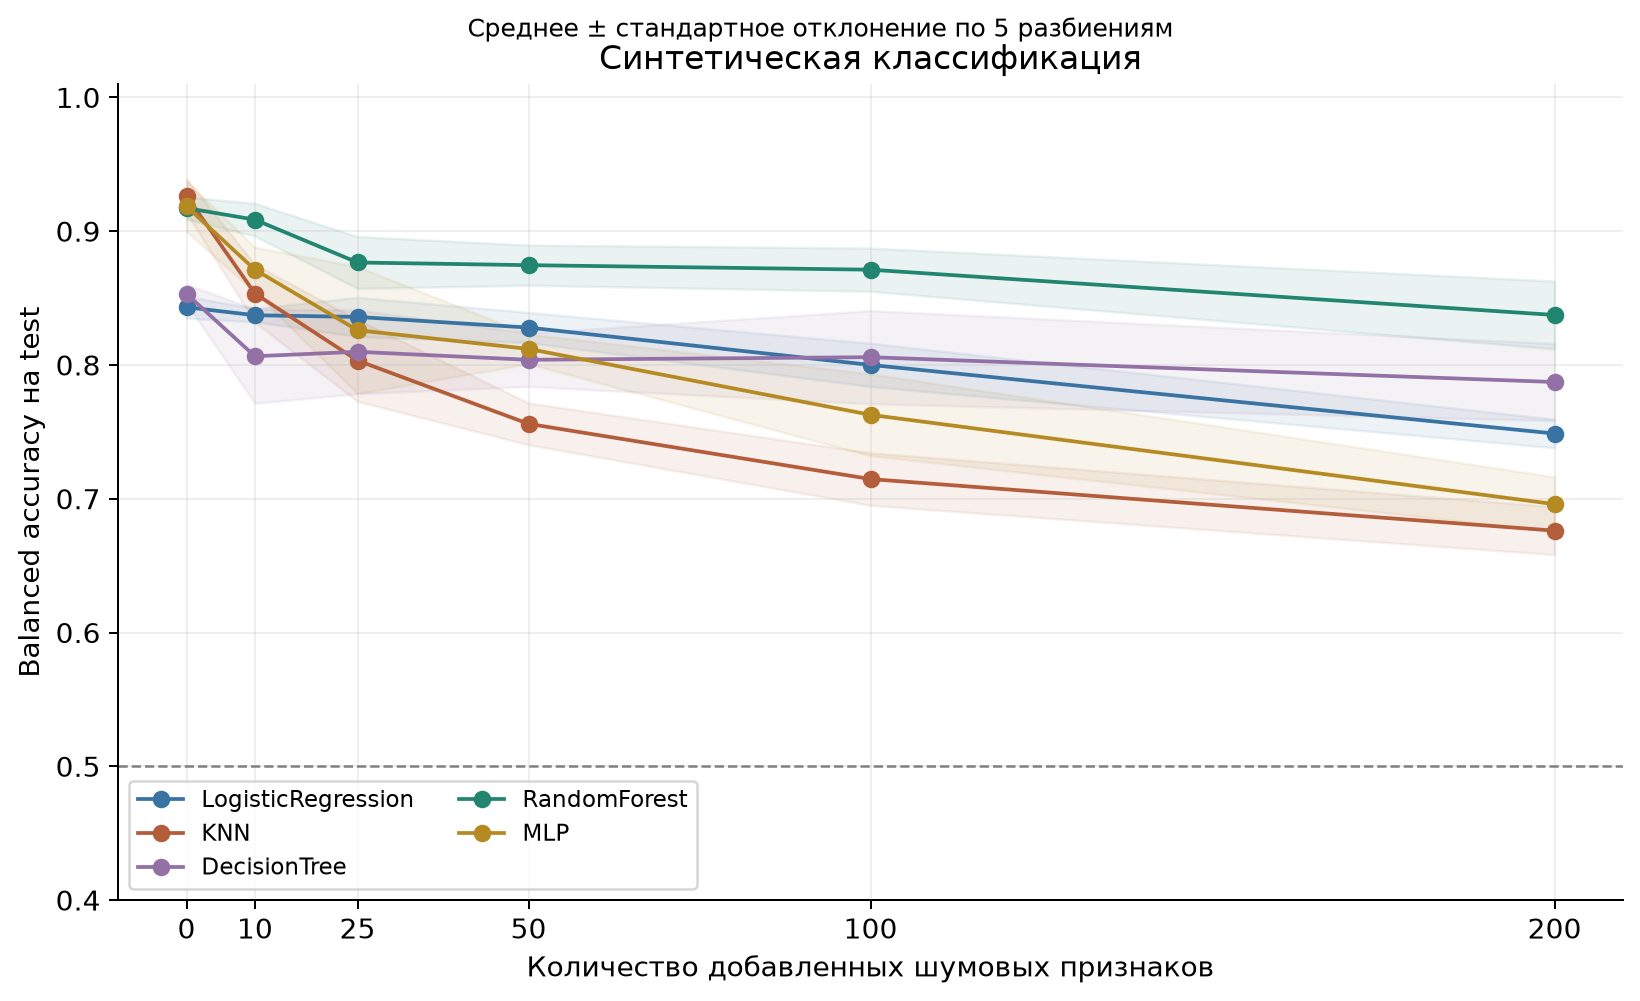

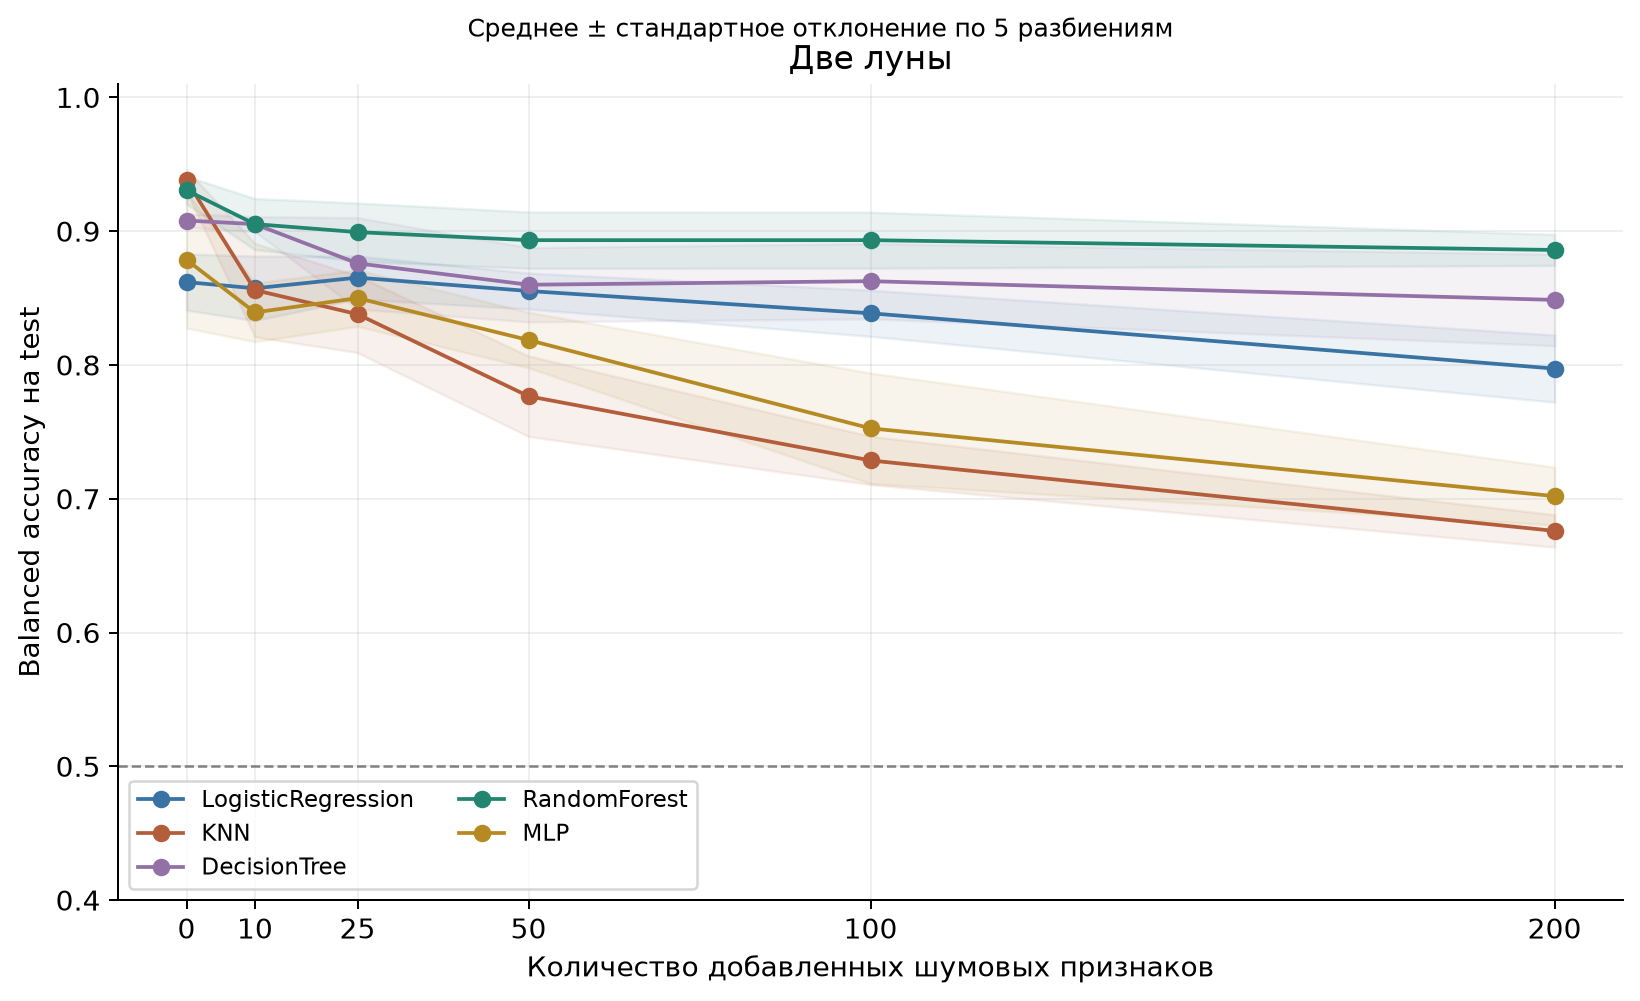

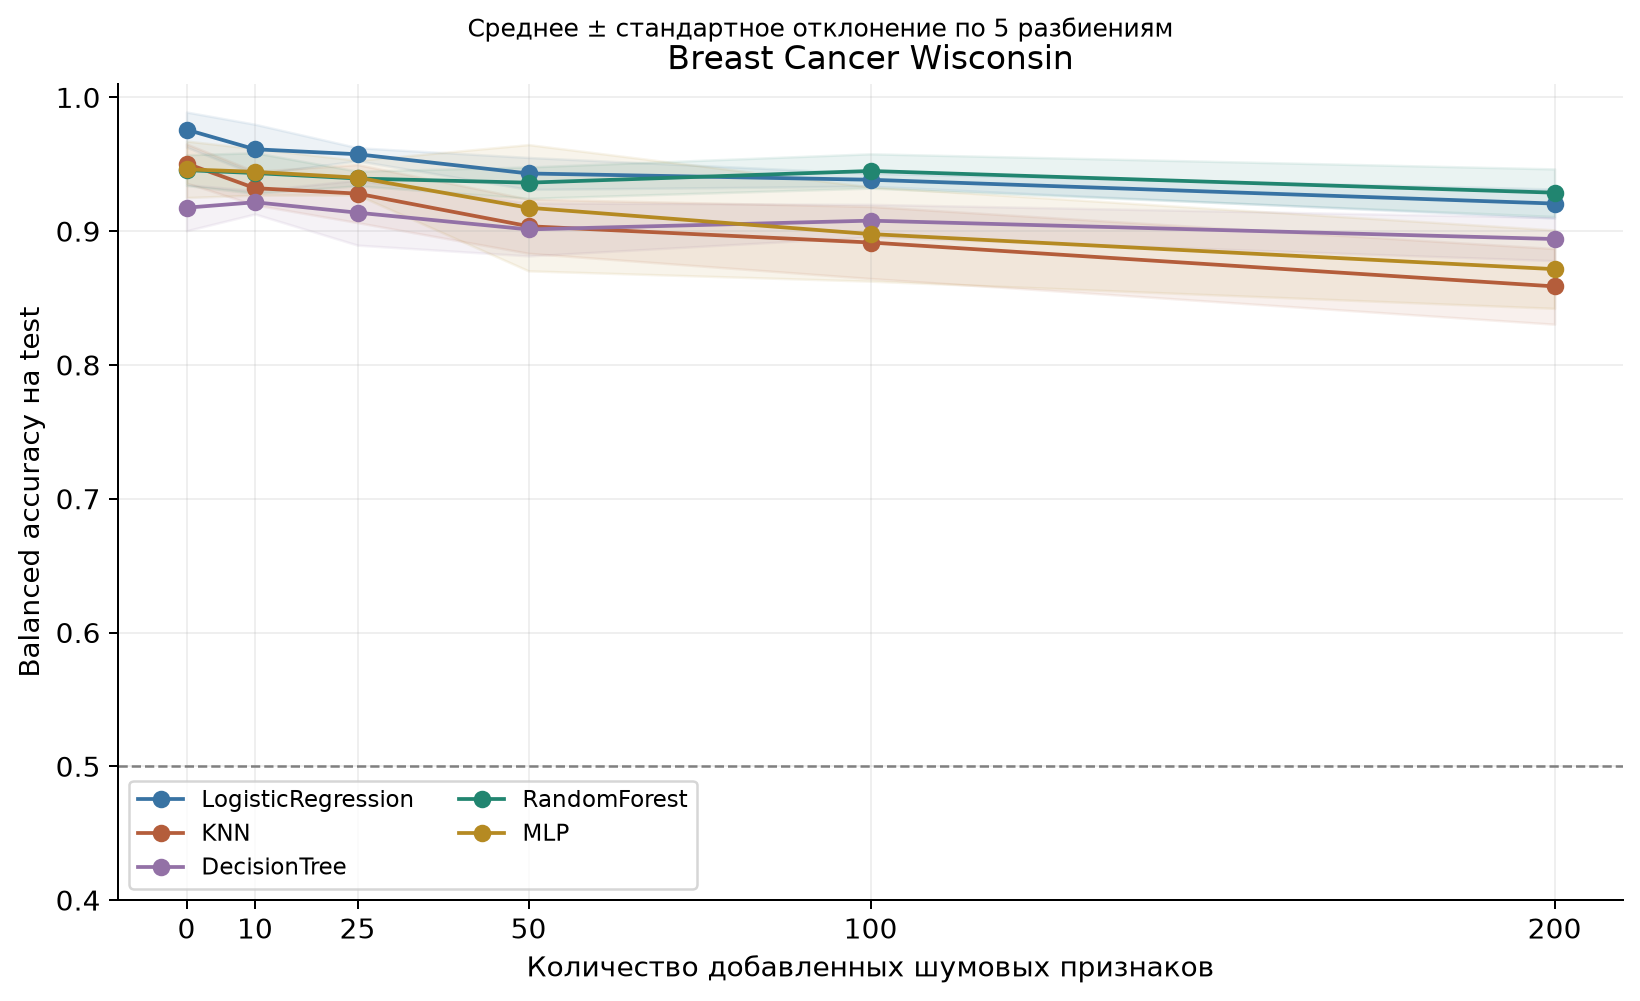

In [8]:
for dataset in LABELS:
    display(Image(filename=str(RESULTS / "figures" / f"quality_{dataset}.png")))

| Данные | Модель | Без добавленного шума | +200 шумовых | Изменение, п.п. |
|---|---|---:|---:|---:|
| Синтетическая классификация | LogisticRegression | 84,3% ± 0.8 | 74,9% ± 1.1 | -9.4 |
| Синтетическая классификация | KNN | 92,6% ± 1.3 | 67,6% ± 1.8 | -25.0 |
| Синтетическая классификация | DecisionTree | 85,3% ± 0.7 | 78,7% ± 2.9 | -6.6 |
| Синтетическая классификация | RandomForest | 91,7% ± 0.8 | 83,7% ± 2.5 | -8.0 |
| Синтетическая классификация | MLP | 91,9% ± 1.9 | 69,6% ± 2.0 | -22.3 |
| Две луны | LogisticRegression | 86,2% ± 2.1 | 79,7% ± 2.5 | -6.5 |
| Две луны | KNN | 93,8% ± 0.8 | 67,6% ± 1.2 | -26.2 |
| Две луны | DecisionTree | 90,8% ± 0.5 | 84,9% ± 3.4 | -5.9 |
| Две луны | RandomForest | 93,1% ± 1.0 | 88,6% ± 1.2 | -4.5 |
| Две луны | MLP | 87,9% ± 5.1 | 70,2% ± 2.2 | -17.7 |
| Breast Cancer Wisconsin | LogisticRegression | 97,6% ± 1.3 | 92,1% ± 1.1 | -5.5 |
| Breast Cancer Wisconsin | KNN | 95,1% ± 1.5 | 85,9% ± 2.8 | -9.2 |
| Breast Cancer Wisconsin | DecisionTree | 91,8% ± 1.7 | 89,4% ± 1.6 | -2.3 |
| Breast Cancer Wisconsin | RandomForest | 94,6% ± 1.1 | 92,9% ± 1.8 | -1.7 |
| Breast Cancer Wisconsin | MLP | 94,6% ± 2.1 | 87,2% ± 2.9 | -7.5 |

При +200 средние оценки всех пяти моделей ниже исходных на всех трёх наборах. У KNN падение самое большое на каждом наборе. Лес устойчивее KNN и MLP во всех трёх задачах; на синтетической классификации одиночное дерево потеряло меньше качества, чем лес. Но одинакового убывания на каждом промежуточном шаге не требуется, а победитель по абсолютному качеству зависит от задачи.

In [9]:
delta = paired[paired.n_noise == 200].groupby(["dataset", "model"]).delta_balanced_accuracy_pp.agg(["mean", "std"])
display(delta.rename(columns={"mean": "Изменение, п.п.", "std": "SD изменения, п.п."}).round(2))

Изменение, п.п.  SD изменения, п.п.
dataset        model                                                  
breast_cancer  DecisionTree                  -2.34                2.55
               KNN                           -9.19                1.89
               LogisticRegression            -5.53                1.96
               MLP                           -7.46                1.32
               RandomForest                  -1.69                0.84
classification DecisionTree                  -6.59                2.21
               KNN                          -25.02                2.36
               LogisticRegression            -9.44                1.30
               MLP                          -22.26                2.79
               RandomForest                  -7.99                2.80
moons          DecisionTree                  -5.93                3.90
               KNN                          -26.20                1.43
               LogisticRegression            -6.47                3.20
               MLP                          -17.67                6.98
               RandomForest                  -4.47                1.02

## 7. Почему KNN чувствителен: простой пример
Объект-запрос `(0,0)`, объект A `(1,0)` и объект B `(3,0)`: A ближе, квадраты расстояний 1 и 9. Добавим по одному шумовому значению: запросу 0, A значение 5, B значение 0. Квадраты расстояний становятся 26 и 9 — ближайший объект меняется. Это иллюстративный пример, а не специально выбранный результат эксперимента.

Для двух независимых стандартных нормальных величин z и z′: `E[(z-z′)²] = Var(z-z′) = 2`. От p независимых шумовых координат ожидаемый вклад в квадрат евклидова расстояния равен 2p. После масштабирования на конечной train-выборке это ориентир, а не точное равенство. Относительный разброс расстояний может уменьшаться: соседей становится труднее отличать по полезным координатам.

До шума: 1.0 9.0
После шума: 26.0 9.0


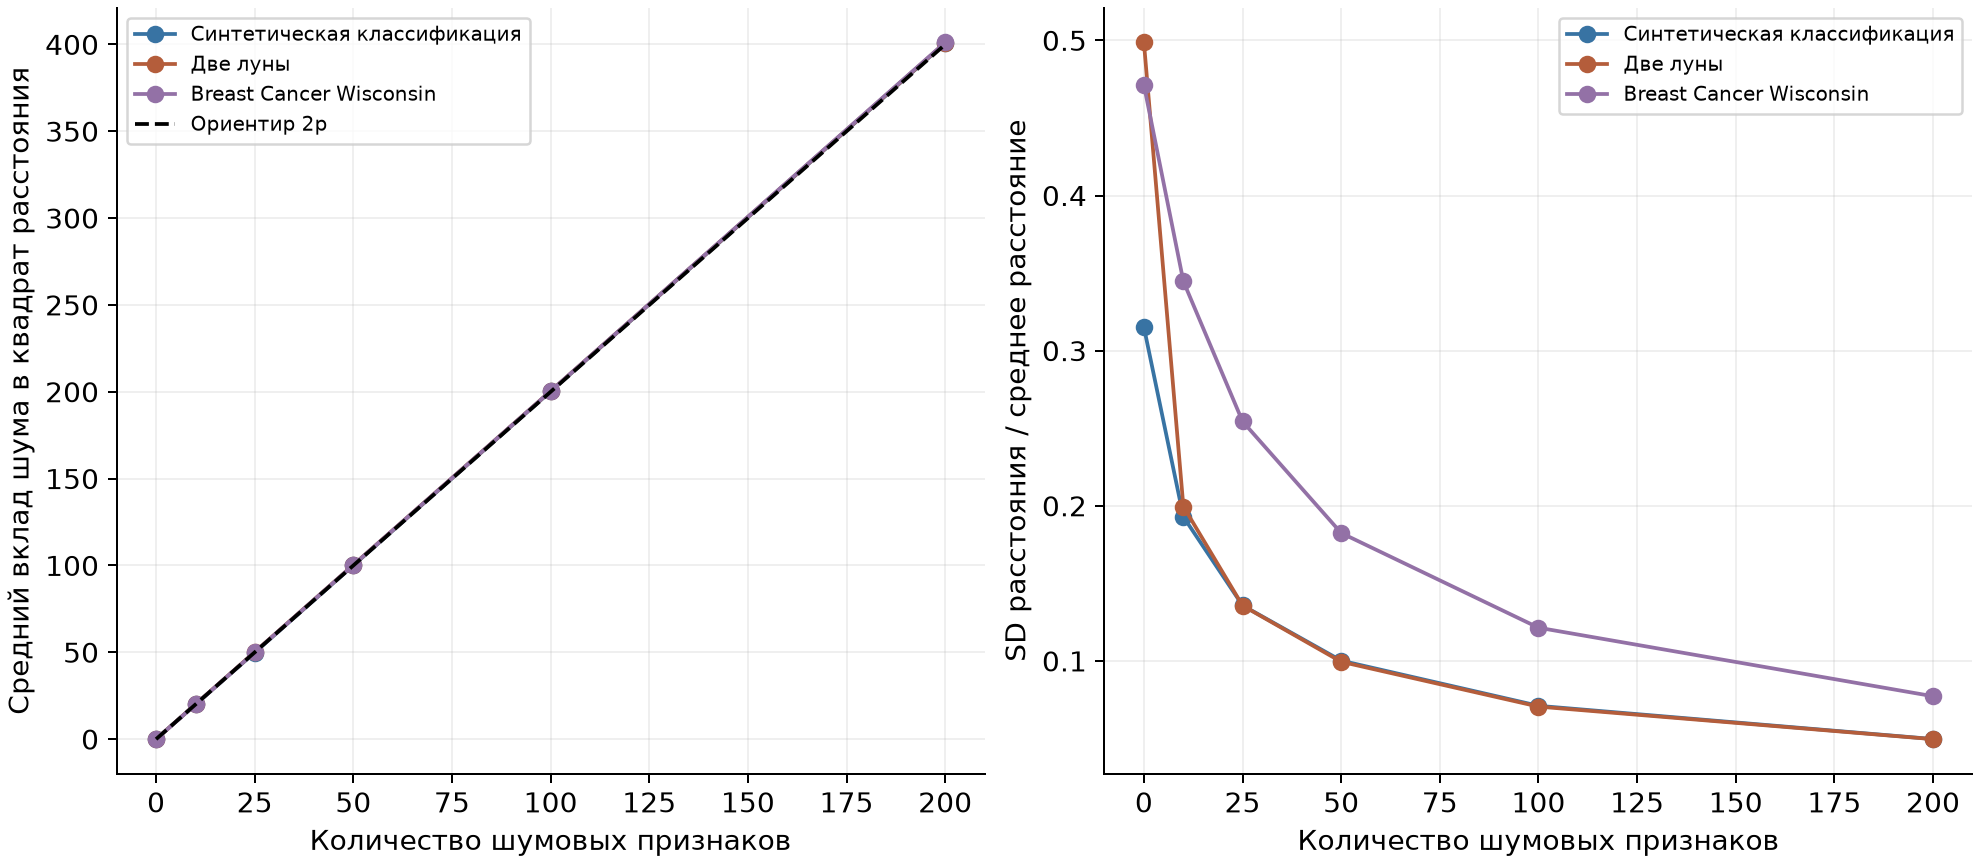

In [10]:
q = np.array([0., 0.]); a = np.array([1., 0.]); b = np.array([3., 0.])
print("До шума:", np.sum((q-a)**2), np.sum((q-b)**2))
print("После шума:", np.sum((np.r_[q,0]-np.r_[a,5])**2), np.sum((np.r_[q,0]-np.r_[b,0])**2))
display(Image(filename=str(RESULTS / "figures" / "distance_geometry.png")))

## 8. Переобучение и шум
Большое качество на обучении само по себе не гарантирует хороших новых ответов. У MLP на лунах с 200 шумовыми признаками средняя accuracy на train 95,1%, на test 70,2%. Модель может подстроиться под случайные закономерности. При этом падение KNN связано также с геометрией расстояний, а не только с объяснением через переобучение. У неограниченного дерева и леса train accuracy достигает 1, но test значительно ниже.

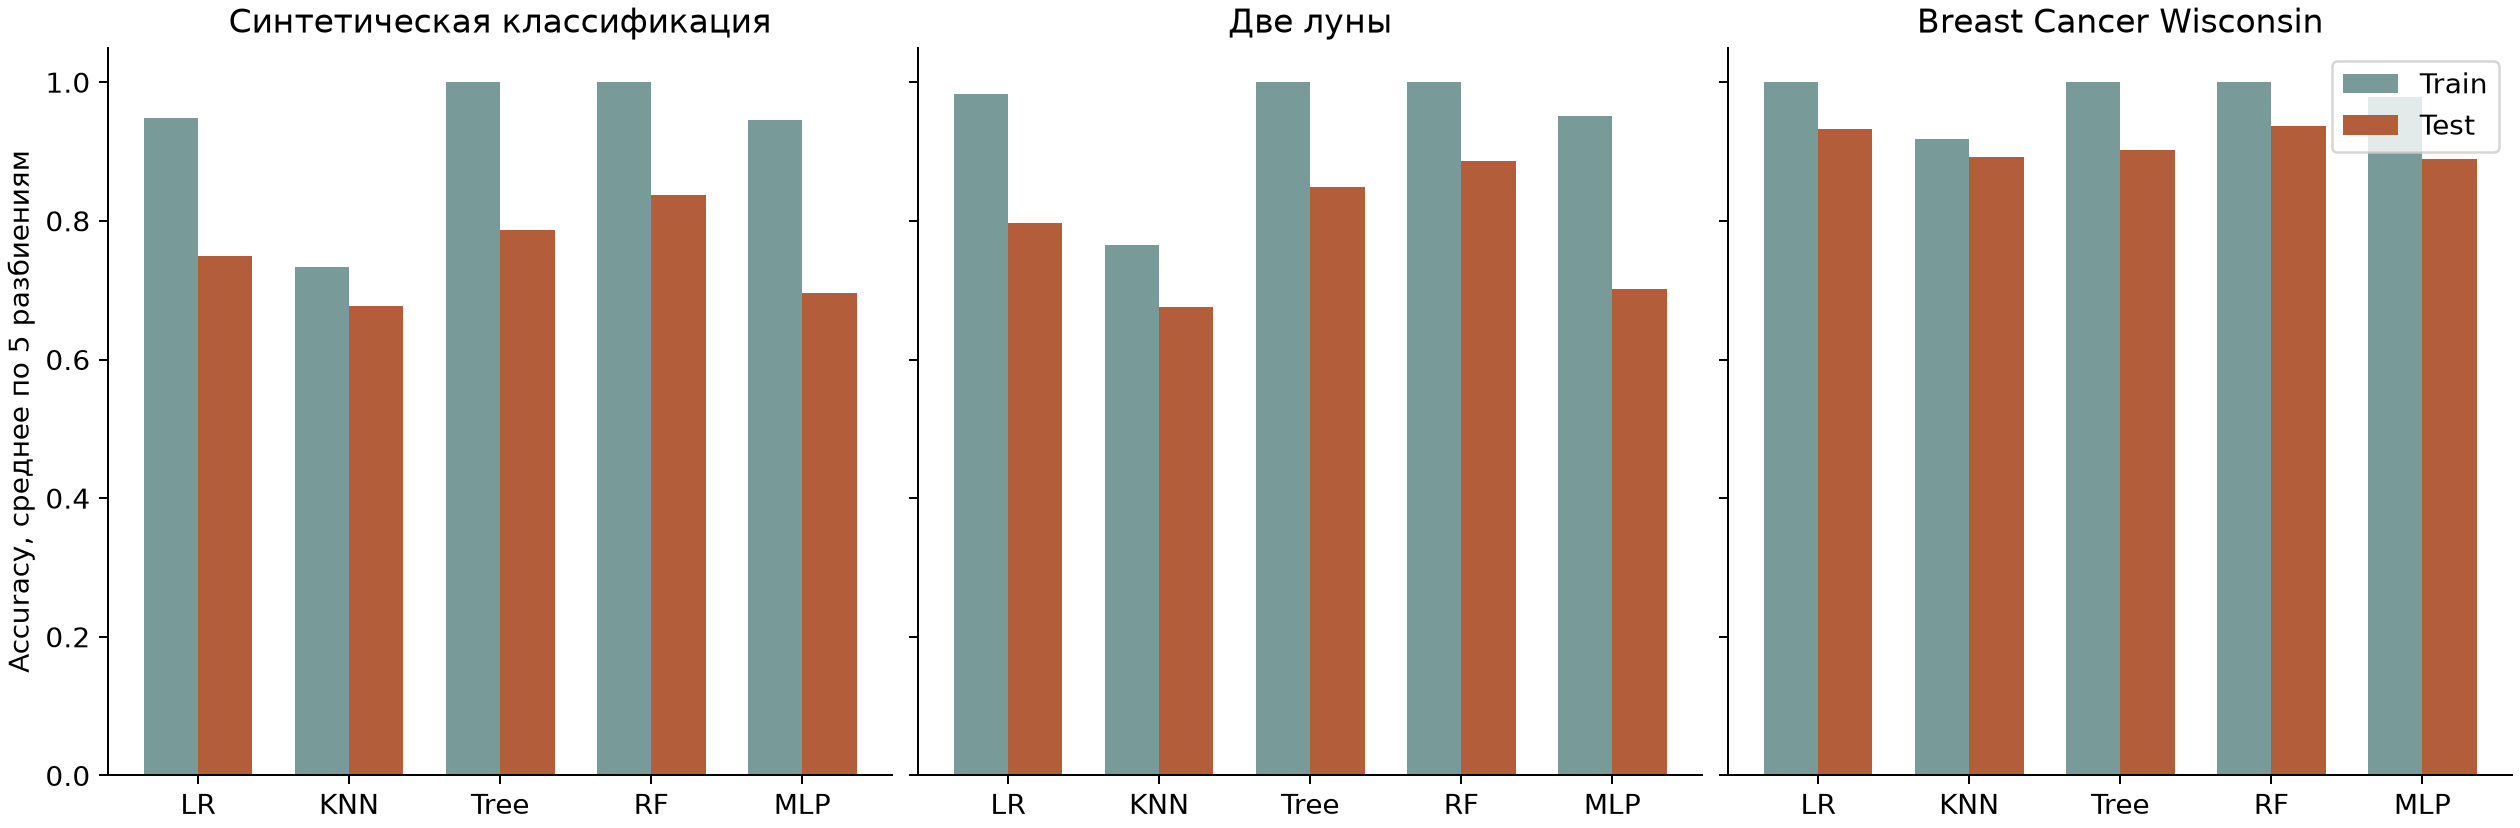

In [11]:
display(Image(filename=str(RESULTS / "figures" / "train_test_gap.png")))

## 9. Отрицательный контроль
Убираем все исходные признаки и оставляем только 200 случайных. Те же метки и разбиения. Если шум действительно независим, устойчиво предсказывать класс по нему невозможно; конечные выборки всё равно дают случайные отклонения от 0,5.

Dummy всегда выбирает наиболее частый класс. На Breast Cancer обычная accuracy такого правила выше 0,5 из-за дисбаланса; balanced accuracy остаётся 0,5.

accuracy  balanced_accuracy
dataset        model                                          
breast_cancer  DecisionTree           0.549              0.522
               Dummy                  0.626              0.500
               KNN                    0.608              0.524
               LogisticRegression     0.511              0.491
               MLP                    0.565              0.508
               RandomForest           0.605              0.491
classification DecisionTree           0.493              0.493
               Dummy                  0.503              0.500
               KNN                    0.493              0.493
               LogisticRegression     0.501              0.501
               MLP                    0.520              0.520
               RandomForest           0.513              0.513
moons          DecisionTree           0.497              0.497
               Dummy                  0.500              0.500
               KNN                    0.505              0.505
               LogisticRegression     0.526              0.526
               MLP                    0.529              0.529
               RandomForest           0.514              0.514

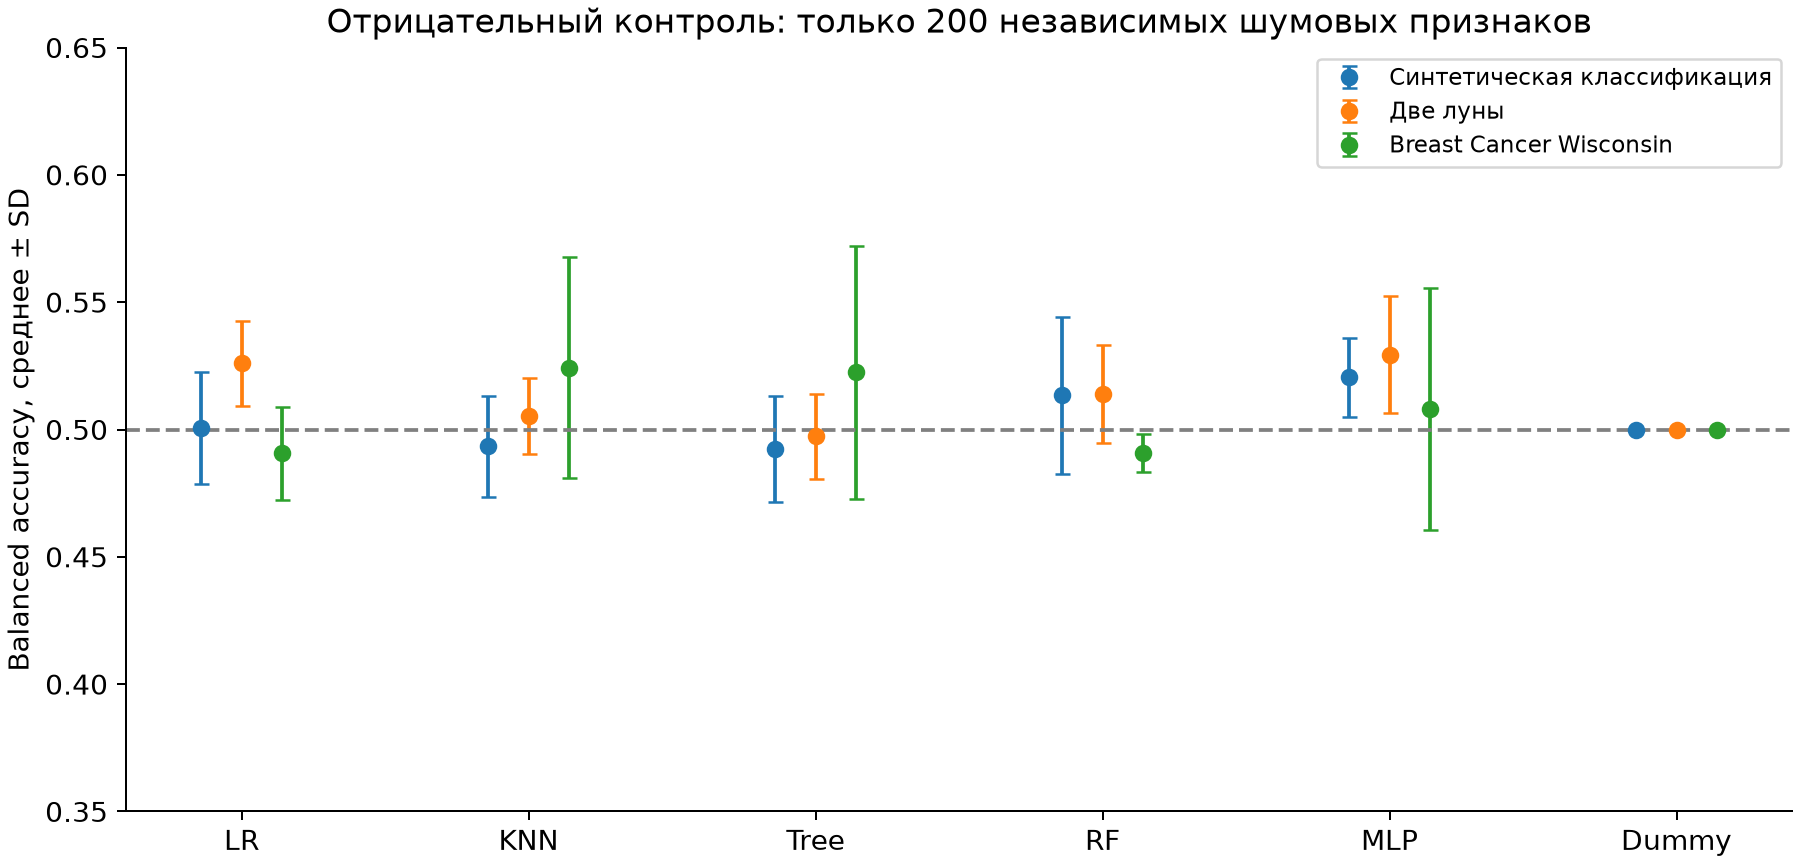

In [12]:
control = pd.read_csv(RESULTS / "noise_only.csv")
display(control.groupby(["dataset", "model"])[["accuracy", "balanced_accuracy"]].mean().round(3))
display(Image(filename=str(RESULTS / "figures" / "noise_only.png")))

## 10. Отбор признаков: проверяем способ уменьшить вред
`f_classif` оценивает для каждого столбца отношение межклассовых различий к внутриклассовому разбросу. `SelectPercentile` оставляет верхнюю долю признаков по этому критерию. Это одномерный отбор: взаимодействия между столбцами не учитываются.

Внутри каждой внешней train-части выполняется 3-fold CV. В каждой внутренней итерации заново обучаются scaler, отбор и KNN; выбирается доля из `[5,10,25,50,100]`. После выбора pipeline переобучается на всём внешнем train и один раз оценивается на внешнем test. Такая схема отделяет выбор настройки от проверки её качества. k=15 не меняется.

,dataset,seed,percentile,selected_original,selected_noise,balanced_accuracy
0,classification,11,5,8,3,0.886173
1,classification,23,5,8,3,0.869661
2,classification,37,5,8,3,0.863083
3,classification,51,5,8,3,0.869616
4,classification,71,5,9,2,0.906351
5,moons,11,5,2,9,0.853333
6,moons,23,5,2,9,0.836667
7,moons,37,5,2,9,0.886667
8,moons,51,5,2,9,0.830000
9,moons,71,5,2,9,0.856667


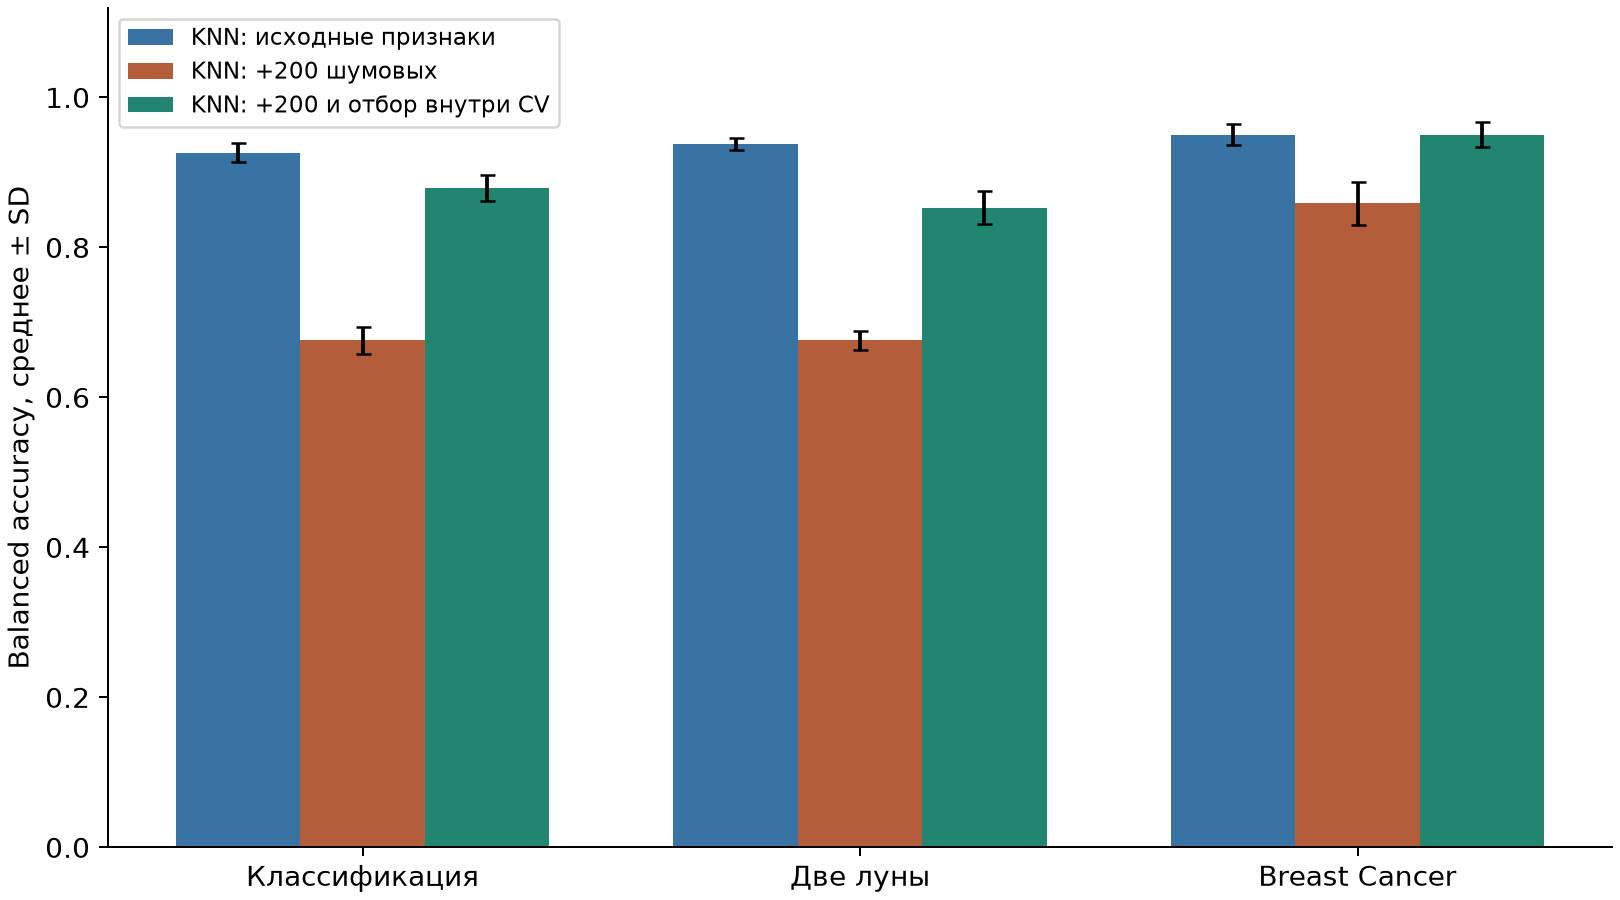

In [13]:
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Эта же конфигурация уже выполнена для всех наборов и seeds в функции run_experiments.
selection_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectPercentile(f_classif)),
    ("model", KNeighborsClassifier(n_neighbors=15)),
])
search = GridSearchCV(selection_pipeline,
    {"select__percentile": [5, 10, 25, 50, 100]},
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=40011),
    scoring="balanced_accuracy", n_jobs=1, error_score="raise")
selection = pd.read_csv(RESULTS / "selection.csv")
display(selection[["dataset", "seed", "percentile", "selected_original", "selected_noise", "balanced_accuracy"]])
display(Image(filename=str(RESULTS / "figures" / "feature_selection.png")))

| Данные | KNN без шума | KNN +200 | KNN +200 и отбор |
|---|---:|---:|---:|
| Синтетическая классификация | 92,6% | 67,6% | 87,9% |
| Две луны | 93,8% | 67,6% | 85,3% |
| Breast Cancer Wisconsin | 95,1% | 85,9% | 95,0% |

Отбор существенно помогает, но не обязан найти идеальный набор. На лунах 5% от 202 признаков оставляют 11 столбцов, из них 9 шумовые. На Breast Cancer выбраны 23 исходных признака и ни одного добавленного шумового. Сведения о происхождении столбцов использованы **после** обучения для анализа, но не передавались селектору.

## 11. Итог и границы выводов
1. В проверенной серии добавление 200 независимых шумовых признаков снижает среднее качество каждой модели на каждом наборе.
2. Чувствительность разная: KNN сильнее страдает от лишних координат; лес потерял меньше качества, чем KNN и MLP, на всех трёх наборах.
3. Стандартизация необходима для ряда моделей, но не превращает шум в полезный сигнал.
4. Отбор помогает только при честной проверке; подбор на test завысил бы оценку.
5. Нельзя обобщать численный рейтинг на все задачи: здесь три небольших набора, пять разбиений, фиксированные настройки и один тип шума. Не проверены систематически рост числа объектов, коррелированный шум и оптимальные гиперпараметры каждого алгоритма.

Практический вывод: добавлять признаки стоит по результатам валидации, а не по принципу «чем больше, тем лучше».

## Источники и воспроизводимость
Все функции, параметры, seeds, версии библиотек и результаты представлены в ячейках этого notebook. Промежуточные файлы создаются автоматически во временной папке; внешние файлы данных не нужны.

- [Документация данных scikit-learn](https://scikit-learn.org/stable/datasets.html).
- [Ошибки оценки и утечка данных](https://scikit-learn.org/stable/common_pitfalls.html).
- [Отбор признаков](https://scikit-learn.org/stable/modules/feature_selection.html).
- [Вложенная оценка подбора параметров](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

Предупреждения сходимости записываются в таблицы; в основной серии их не было. При повторении на иной платформе или версиях библиотек возможны небольшие численные отличия.